In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0018333688702864771 + 0.0007209712160215784im 0.0011328176997066858 + 0.00040804519819399453im … -7.165117837685901e-5 - 0.0024352300160786974im 0.0012287994652867916 - 0.0007128973523970242im; -0.0003815175820205098 - 0.0027546760043193463im -0.00025230479498801126 - 0.0023304299788320898im … -0.0017172479577062044 - 0.0007898022660768014im -0.0019516767487570048 + 0.0033702186847735923im; -0.0034379775155787655 + 0.001174688735776502im 0.002980213301755901 + 0.0008345764267142128im … -0.001638347856233644 + 0.0035370929291710495im -0.002116214482661205 + 0.000710368816396814im;;; -0.0035760050163433418 + 7.117210938570343e-5im 0.003063455232955372 - 0.0020559114467753508im … -0.0023346978475534104 - 0.0031635259793381253im 0.0020563500869815866 + 0.0015265869024742424im; -0.003889243310280841 - 0.00043066185372638027im 0.0034955785063485382 + 0.0026583233009469165im … -0.0017916522705165062 - 0.004090860885

In [3]:
P=Onestep()
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)
W2=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [0.023405430830628658 + 0.0im -1.2461571214242095 + 0.0im -1.1534427815505566 + 0.0im -0.9981709002673298 + 0.0im; -0.8444536166680037 + 0.0im 2.2198459574027787 + 0.0im -0.09613903299129796 + 0.0im 0.2680079748739545 + 0.0im; -2.7638719828547647 + 0.0im -1.1603591103574928 + 0.0im 1.6672282879490297 + 0.0im -1.5273079148188862 + 0.0im; -0.19679461805156614 + 0.0im 0.8693977541858723 + 0.0im 0.9724350217856964 + 0.0im -0.2717982525173601 + 0.0im]
 [-0.17258738627666084 + 0.0im 0.5965737129362696 + 0.0im 0.17924156437341734 + 0.0im -1.0497317605510301 + 0.0im; -0.005182939658480218 + 0.0im -1.8443276273966678 + 0.0im -1.307912427931483 + 0.0im -0.34953005566630513 + 0.0im; 1.968543315157029 + 0.0im 0.9502164167871463 + 0.0im 0.17130867595767665 + 0.0im 0.36847352321357946 + 0.0im; -0.9181786121833845 + 0.0im -0.35740887853206227 + 0.0im -0.10435399697122318 + 0.0im 0.08680308923983193 + 0.0im]
 [0.03742851704776901 + 0.0im -0.6531792576843067 + 0.0im 2.43

In [4]:
layer1=CPTC_Layer(hop,W1)
Norm=NormLayer()
layer2=PTC_Layer(hop,W2)
act=Softmax()
layer1=test_Layer(layer1,sqrt(length(x)) ,t, act,true)
layers=[layer1,Norm,layer2]

3-element Vector{LMP.Layer_types.Layer}:
 test_Layer(CPTC_Layer(Spin_matrix[[0.055971992173154336 + 0.0im -1.7533721105936473 + 0.0im -0.9045640987452669 + 0.0im -0.3419255982995048 + 0.0im; 0.8057405098887781 + 0.0im -0.46578353801023936 + 0.0im -0.7509206676028597 + 0.0im 1.3506664171181695 + 0.0im; 2.486826112953175 + 0.0im -0.6466496480583781 + 0.0im -0.4913974048588158 + 0.0im -1.55240590140239 + 0.0im; 0.03895104769358676 + 0.0im -0.19170265119147267 + 0.0im 1.9849739715613104 + 0.0im -2.037205330816145 + 0.0im], [-0.6996995270715217 + 0.0im -1.05776372598793 + 0.0im -0.8904894439057335 + 0.0im -1.0458316696200463 + 0.0im; 0.19750544163223283 + 0.0im 0.006624298675264174 + 0.0im -0.7355789263974916 + 0.0im -2.0139305312941826 + 0.0im; -0.8245693716579559 + 0.0im 0.8053398686939718 + 0.0im -0.3613317199587911 + 0.0im 0.8931669294853487 + 0.0im; -1.8190051917605268 + 0.0im -0.9689869826418493 + 0.0im 1.4031120517317983 + 0.0im -0.8327976659262548 + 0.0im], [-0.8317748943958777 + 0.

In [5]:
opt=Adam()
opt.α=0.05

0.05

In [6]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[6.033437655398192e-6 - 2.365590937541699e-6im 4.8745092288042143e-8 - 1.1302849746503804e-5im … 9.785440267023985e-6 + 5.821172886122586e-6im -1.1332878419852815e-6 - 1.1948011641482957e-5im; -4.183889842957525e-6 - 8.375235248137046e-6im -4.258216367585542e-6 - 3.163307679334672e-6im … 1.8602694521968515e-6 - 2.938411550817296e-6im 1.2258369480817082e-6 + 2.9572869742067494e-7im; 3.7767335346140846e-6 - 5.148461854235026e-6im 8.99627982136945e-6 - 1.1204689051764668e-5im … 5.860505039139562e-6 - 9.05697386345359e-6im -6.7029041638487895e-6 + 3.1517980555303903e-6im;;; -1.2609426910290672e-6 - 5.153999439037959e-6im -9.690300272036917e-6 + 2.01678848719576e-6im … 8.468143749939323e-6 - 1.737087563904551e-6im -8.00808569472547e-6 + 3.170915873033624e-6im; -6.197386965176423e-6 - 1.3822248646485824e-5im -1.9956744665799526e-6 - 8.0163943063937e-6im … -1.809756778824657e-5 + 4.3957314423438255e-6im -9.459839595651

In [7]:
# @load "PTC_weight.jld2" W
# layer2.W=W
# xavier_init!(layer1.W,2*length(x))

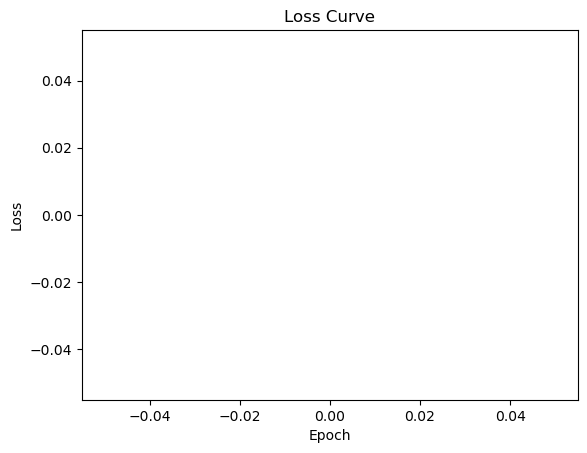

Epoch: 1, Loss: 38.07639326261785 + 0.0im
Epoch: 2, Loss: 33.39712692866315 + 0.0im
Epoch: 3, Loss: 29.26310363361153 + 0.0im
Epoch: 4, Loss: 25.193394223724077 + 0.0im
Epoch: 5, Loss: 21.556665753805596 + 0.0im
Epoch: 6, Loss: 18.33544119050906 + 0.0im
Epoch: 7, Loss: 15.35611095374265 + 0.0im
Epoch: 8, Loss: 12.732154146797116 + 0.0im
Epoch: 9, Loss: 10.479467814914301 + 0.0im
Epoch: 10, Loss: 8.601910894999243 + 0.0im
Epoch: 11, Loss: 7.051693307262131 + 0.0im
Epoch: 12, Loss: 5.812638805425495 + 0.0im
Epoch: 13, Loss: 4.83880427768373 + 0.0im
Epoch: 14, Loss: 4.047362556779433 + 0.0im
Epoch: 15, Loss: 3.4226858752517306 + 0.0im
Epoch: 16, Loss: 2.9070393869365523 + 0.0im
Epoch: 17, Loss: 2.520583144175197 + 0.0im
Epoch: 18, Loss: 2.211980277229337 + 0.0im
Epoch: 19, Loss: 1.988054103450281 + 0.0im
Epoch: 20, Loss: 1.8258098266502851 + 0.0im
Epoch: 21, Loss: 1.709017021785601 + 0.0im
Epoch: 22, Loss: 1.6824370267199675 + 0.0im
Epoch: 23, Loss: 1.6760065208768586 + 0.0im
Epoch: 24, L

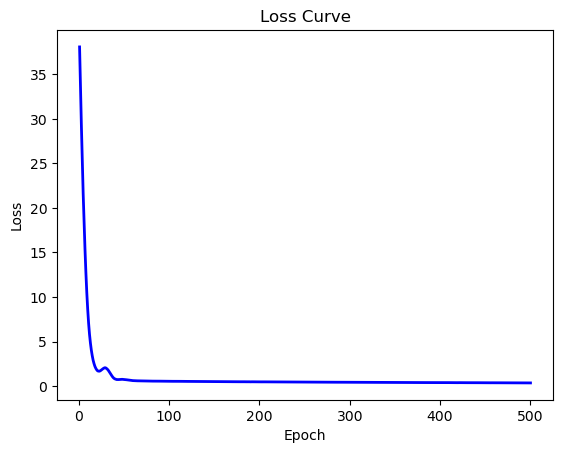

In [8]:
train(opt,layers,x,t,D,epochs=500)

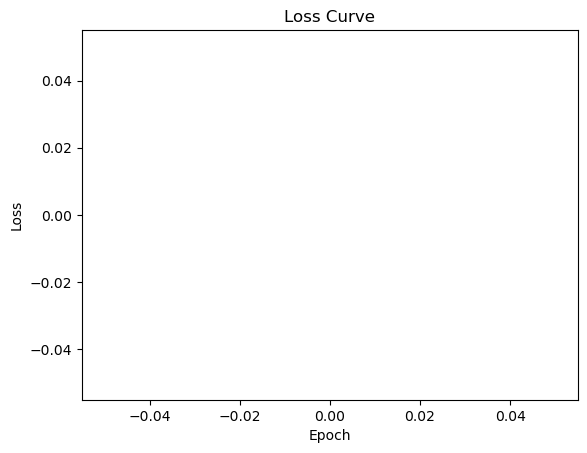

Epoch: 1, Loss: 0.36209652225425254 + 0.0im
Epoch: 2, Loss: 0.3627222365064536 + 0.0im
Epoch: 3, Loss: 0.36227427123097633 + 0.0im
Epoch: 4, Loss: 0.36170914473163046 + 0.0im
Epoch: 5, Loss: 0.35710027950873674 + 0.0im
Epoch: 6, Loss: 0.36008267817327205 + 0.0im
Epoch: 7, Loss: 0.3591033544367789 + 0.0im
Epoch: 8, Loss: 0.36005136835410273 + 0.0im
Epoch: 9, Loss: 0.3606166009624172 + 0.0im
Epoch: 10, Loss: 0.3585148192416403 + 0.0im
Epoch: 11, Loss: 0.3605587175354451 + 0.0im
Epoch: 12, Loss: 0.35634111149585773 + 0.0im
Epoch: 13, Loss: 0.35892472195724123 + 0.0im
Epoch: 14, Loss: 0.35736416804523286 + 0.0im
Epoch: 15, Loss: 0.35687809196814557 + 0.0im
Epoch: 16, Loss: 0.35823959142553236 + 0.0im
Epoch: 17, Loss: 0.35755244792041724 + 0.0im
Epoch: 18, Loss: 0.36034351520398006 + 0.0im
Epoch: 19, Loss: 0.3535074778470452 + 0.0im
Epoch: 20, Loss: 0.3588832539085786 + 0.0im
Epoch: 21, Loss: 0.35404341729970545 + 0.0im
Epoch: 22, Loss: 0.35475381436270187 + 0.0im
Epoch: 23, Loss: 0.3550325

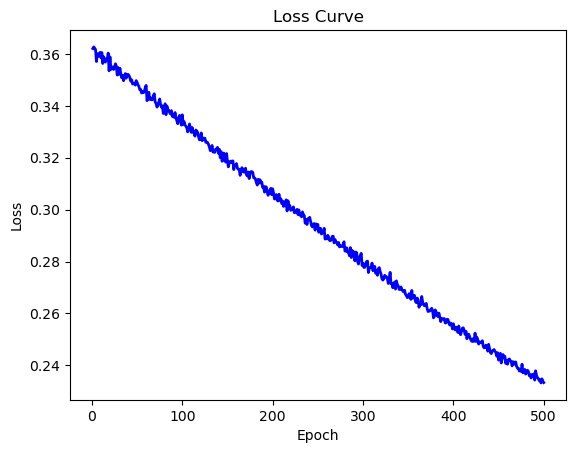

In [9]:
train(opt,layers,x,t,D,epochs=500)

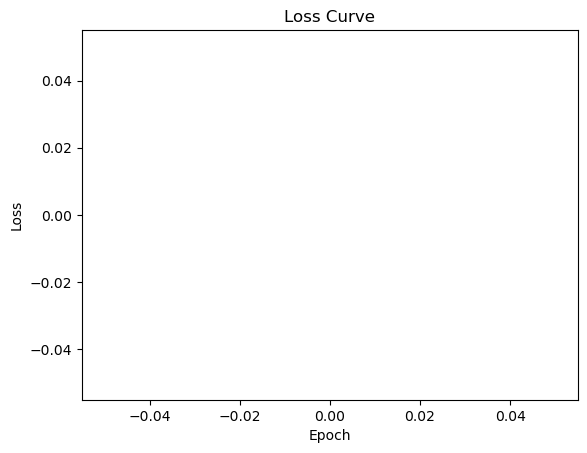

Epoch: 1, Loss: 0.23574106963512168 + 0.0im
Epoch: 2, Loss: 0.23391026984322236 + 0.0im
Epoch: 3, Loss: 0.23248070989430827 + 0.0im
Epoch: 4, Loss: 0.23433380351393895 + 0.0im
Epoch: 5, Loss: 0.23274600981931023 + 0.0im
Epoch: 6, Loss: 0.23242814138042636 + 0.0im
Epoch: 7, Loss: 0.23223528692607434 + 0.0im
Epoch: 8, Loss: 0.23216593441078662 + 0.0im
Epoch: 9, Loss: 0.2300373581693065 + 0.0im
Epoch: 10, Loss: 0.23018849893943677 + 0.0im
Epoch: 11, Loss: 0.23101761929566242 + 0.0im
Epoch: 12, Loss: 0.22863931361598439 + 0.0im
Epoch: 13, Loss: 0.23076625754960417 + 0.0im
Epoch: 14, Loss: 0.22892397966826583 + 0.0im
Epoch: 15, Loss: 0.23091930824083956 + 0.0im
Epoch: 16, Loss: 0.22911849905467008 + 0.0im
Epoch: 17, Loss: 0.22944474101271292 + 0.0im
Epoch: 18, Loss: 0.23121658692589833 + 0.0im
Epoch: 19, Loss: 0.23059473355851673 + 0.0im
Epoch: 20, Loss: 0.22942319195347322 + 0.0im
Epoch: 21, Loss: 0.2306379476675176 + 0.0im
Epoch: 22, Loss: 0.23049067719577376 + 0.0im
Epoch: 23, Loss: 0.22

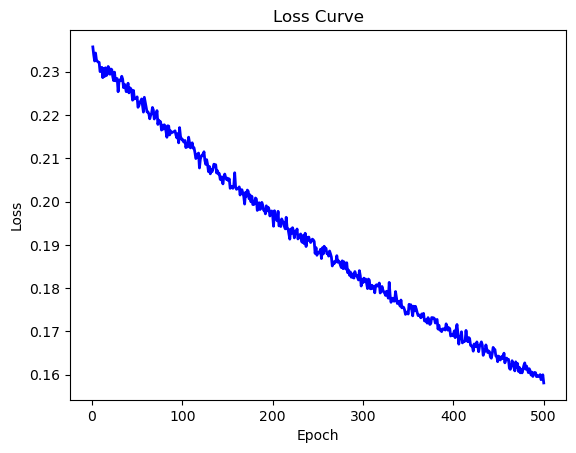

In [10]:
train(opt,layers,x,t,D,epochs=500)

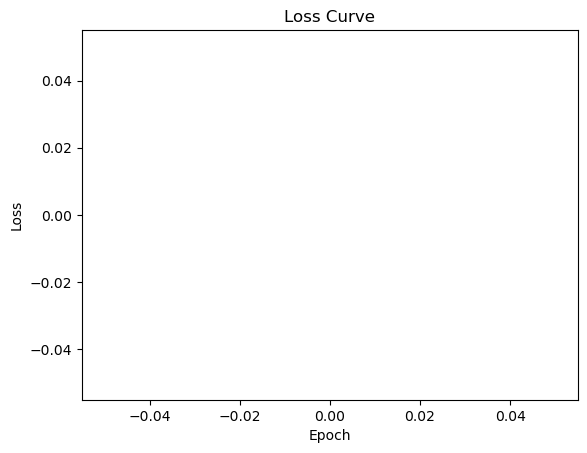

Epoch: 1, Loss: 0.16031919663066932 + 0.0im
Epoch: 2, Loss: 0.1601480529046229 + 0.0im
Epoch: 3, Loss: 0.15816151179747132 + 0.0im
Epoch: 4, Loss: 0.15885898057274875 + 0.0im
Epoch: 5, Loss: 0.15742311380828353 + 0.0im
Epoch: 6, Loss: 0.15764684091447254 + 0.0im
Epoch: 7, Loss: 0.15792691275292547 + 0.0im
Epoch: 8, Loss: 0.158767244197385 + 0.0im
Epoch: 9, Loss: 0.1574755877003015 + 0.0im
Epoch: 10, Loss: 0.1584905748566389 + 0.0im
Epoch: 11, Loss: 0.15882714941499718 + 0.0im
Epoch: 12, Loss: 0.1584600667297638 + 0.0im
Epoch: 13, Loss: 0.1575681601625552 + 0.0im
Epoch: 14, Loss: 0.15773847736104435 + 0.0im
Epoch: 15, Loss: 0.15697214064467324 + 0.0im
Epoch: 16, Loss: 0.15781347223045952 + 0.0im
Epoch: 17, Loss: 0.15740661059948227 + 0.0im
Epoch: 18, Loss: 0.15815614730000627 + 0.0im
Epoch: 19, Loss: 0.1572018561379909 + 0.0im
Epoch: 20, Loss: 0.15684311968919598 + 0.0im
Epoch: 21, Loss: 0.15798655073281367 + 0.0im
Epoch: 22, Loss: 0.15582011195063908 + 0.0im
Epoch: 23, Loss: 0.15816399

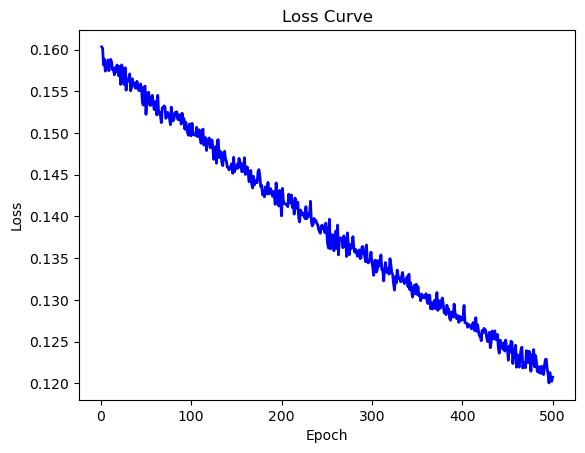

In [11]:
train(opt,layers,x,t,D,epochs=500)

In [12]:
using JLD2

In [14]:
@save "t_layer.jld2" layers